# Notebook 1: Data overview, data quality and choosing the focus crops

**Project:** Sell Now or Store? Predicting the best time to sell crops in Karnataka's mandis

**Data:** Agmarknet variety-wise daily mandi prices (Directorate of Marketing and Inspection, Government of India),
Karnataka only, extracted from the full all-India files with `extract_karnataka.py`.

This notebook answers three questions before any modelling:
1. **How much data is there?** Years, markets, districts and crops covered.
2. **How clean is it?** Counts of each data-quality problem (fixed later, in Notebook 2).
3. **Which crops should the project focus on?** Every crop is ranked by how much its price swings within a year,
   then checked for whether it can be stored. The sell-or-store decision only makes sense for crops that are
   both volatile and storable.

Folder layout: this notebook goes in `fds/notebooks/`, and the data file in `fds/data/karnataka_all_years.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = "../data/karnataka_all_years.csv"   # notebooks/ and data/ sit side by side in fds/

# Chart style: one blue for single-series charts, recessive grey grid and text
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 10,
})
pd.set_option("display.width", 160)

## 1. Load the data
Text columns are loaded as `category` to keep memory low (about 200 MB instead of over 1 GB).

In [2]:
text_cols = ["State", "District", "Market", "Commodity", "Variety", "Grade", "Source_File"]
df = pd.read_csv(DATA_FILE, parse_dates=["Arrival_Date"], dtype={c: "category" for c in text_cols})

print(f"Rows: {len(df):,}")
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
print("Date range:", df["Arrival_Date"].min().date(), "to", df["Arrival_Date"].max().date())
df.head()

Rows: 3,806,941
Memory used: 190 MB
Date range: 2001-01-10 to 2026-04-13


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code,Source_File
0,Karnataka,Dharwad,Hubli (Amaragol),Sunflower,Sunflower,FAQ,2001-01-10,1409.0,1409.0,1409.0,14,2001.csv
1,Karnataka,Dharwad,Hubli (Amaragol),Maize,Local,FAQ,2001-01-10,420.0,445.0,440.0,4,2001.csv
2,Karnataka,Dharwad,Hubli (Amaragol),Onion,Telagi,FAQ,2001-01-10,50.0,300.0,250.0,23,2001.csv
3,Karnataka,Dharwad,Hubli (Amaragol),Wheat,White,FAQ,2001-01-10,771.0,771.0,771.0,1,2001.csv
4,Karnataka,Dharwad,Hubli (Amaragol),Black Gram (Urd Beans)(Whole),Black Gram (Whole),FAQ,2001-01-10,1380.0,1380.0,1380.0,8,2001.csv


## 2. How much data is there?

In [3]:
summary = pd.Series({
    "Rows": len(df),
    "Commodities": df["Commodity"].nunique(),
    "Varieties": df["Variety"].nunique(),
    "Markets (mandis)": df["Market"].nunique(),
    "Districts": df["District"].nunique(),
    "First date": df["Arrival_Date"].min().date(),
    "Last date": df["Arrival_Date"].max().date(),
})
summary.to_frame("Value")

,Value
Rows,3806941
Commodities,214
Varieties,429
Markets (mandis),320
Districts,27
First date,2001-01-10
Last date,2026-04-13


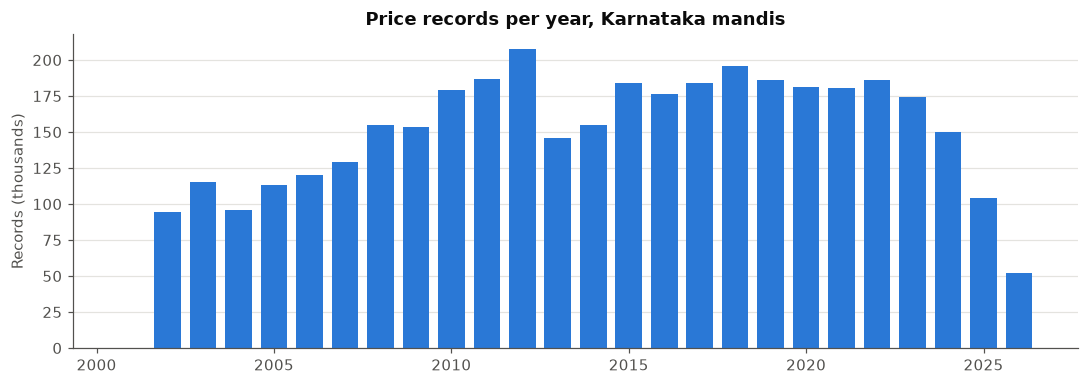

In [4]:
per_year = df["Arrival_Date"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(per_year.index, per_year.values / 1000, color=BLUE, width=0.75)
ax.set_title("Price records per year, Karnataka mandis")
ax.set_ylabel("Records (thousands)")
ax.set_xlabel("")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Rows per month.** The heat map shows where data is missing: darker means more records in that month.
Gaps here become part of the missing-value analysis in Notebook 2.

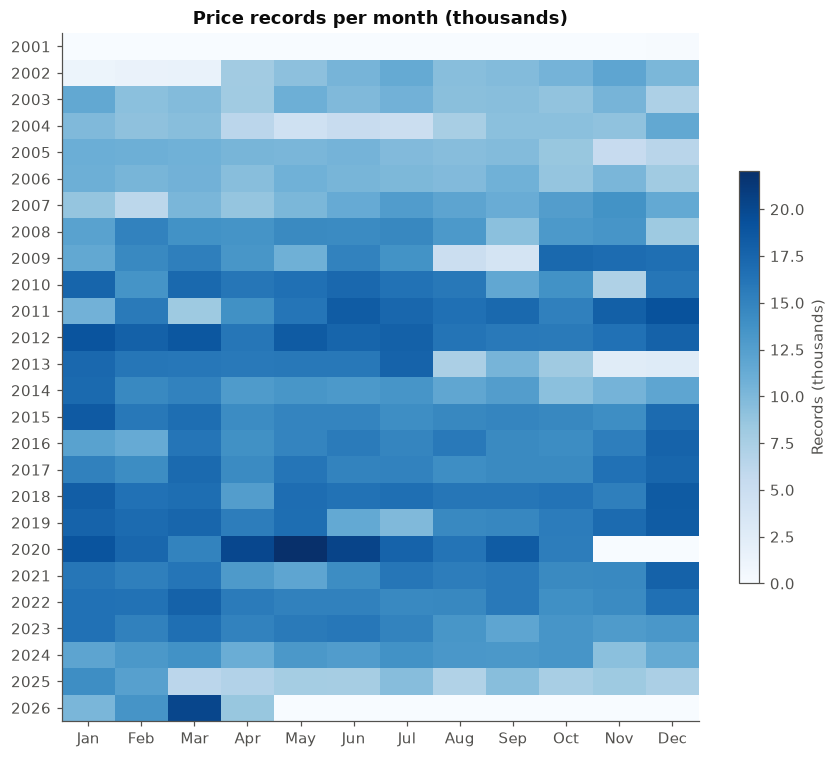

Median records per month: 13,414
Months with less than 25% of the median (likely gaps):
year  month
2001  1          12
      2           0
      3           0
      4           0
      5           0
      6           0
      7           4
      8          56
      9          23
      10         11
      11         22
      12        138
2002  1        1176
      2        1426
      3        1531
2013  11       2573
      12       2709
2020  11          0
      12          0


In [5]:
monthly = (df.assign(year=df["Arrival_Date"].dt.year, month=df["Arrival_Date"].dt.month)
              .groupby(["year", "month"]).size().unstack(fill_value=0)
              .reindex(columns=range(1, 13), fill_value=0))

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(monthly.values / 1000, aspect="auto", cmap="Blues")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(monthly.index))); ax.set_yticklabels(monthly.index)
ax.grid(False)
ax.set_title("Price records per month (thousands)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Records (thousands)")
plt.tight_layout(); plt.show()

median_month = monthly.stack().median()
last = df["Arrival_Date"].max()
thin = monthly.stack()
thin = thin[(thin < 0.25 * median_month)
            & np.array([pd.Timestamp(y, m, 1) <= last for y, m in thin.index])]   # ignore months after the data ends
print(f"Median records per month: {median_month:,.0f}")
print("Months with less than 25% of the median (likely gaps):")
print(thin.rename("records").to_string())

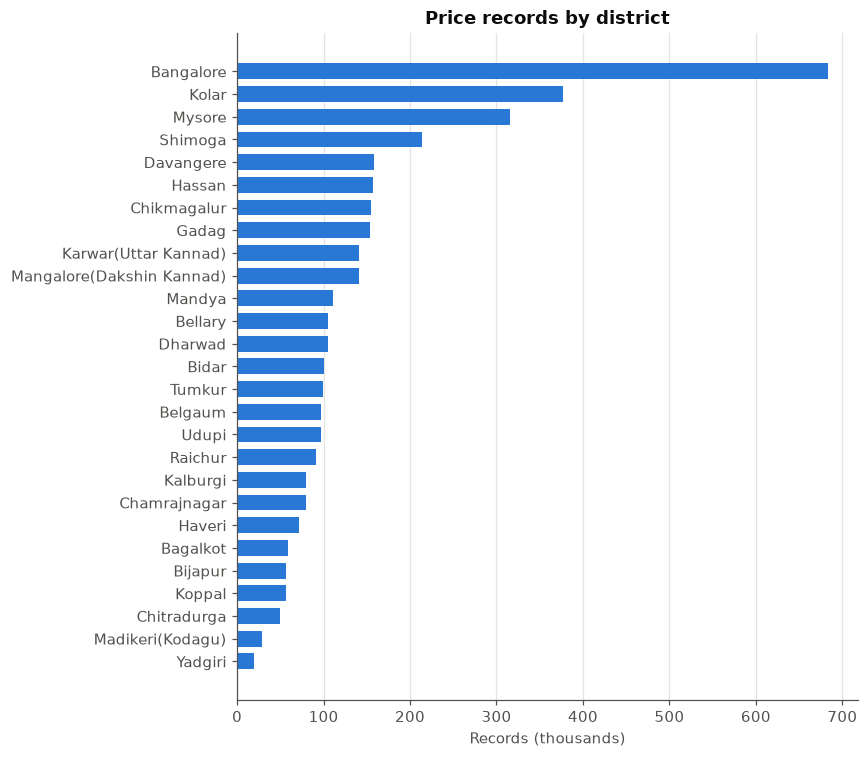

In [6]:
by_district = df["District"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_district.index.astype(str), by_district.values / 1000, color=BLUE, height=0.7)
ax.set_title("Price records by district")
ax.set_xlabel("Records (thousands)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 3. How clean is it?

These are counts only. Each problem is treated in Notebook 2 (cleaning, missing values, outliers).
A price row is treated as **valid** only if all of these hold: minimum and maximum price above zero,
minimum not above maximum, and modal price between minimum and maximum.

In [7]:
key = ["Market", "Commodity", "Variety", "Grade", "Arrival_Date"]
price_cols = ["Min_Price", "Max_Price", "Modal_Price"]
checks = pd.Series({
    "Exact duplicate rows": df.duplicated(subset=[c for c in df.columns if c != "Source_File"]).sum(),
    "Same market + crop + variety + grade + date, repeated": df.duplicated(subset=key).sum(),
    "Blank dates": df["Arrival_Date"].isna().sum(),
    "Min price zero or negative": (df["Min_Price"] <= 0).sum(),
    "Max price zero or negative": (df["Max_Price"] <= 0).sum(),
    "Modal price zero or negative": (df["Modal_Price"] <= 0).sum(),
    "Min price above max price": (df["Min_Price"] > df["Max_Price"]).sum(),
    "Modal price outside min-max range": ((df["Modal_Price"] < df["Min_Price"]) | (df["Modal_Price"] > df["Max_Price"])).sum(),
    "Blank values in price columns": df[price_cols].isna().sum().sum(),
})
quality = checks.to_frame("Rows")
quality["% of all rows"] = (quality["Rows"] / len(df) * 100).round(3)
quality

,Rows,% of all rows
Exact duplicate rows,0,0.000
"Same market + crop + variety + grade + date, repeated",380,0.010
Blank dates,0,0.000
Min price zero or negative,3787,0.099
Max price zero or negative,3046,0.080
Modal price zero or negative,0,0.000
Min price above max price,319,0.008
Modal price outside min-max range,3109,0.082
Blank values in price columns,0,0.000


## 4. Which crops should the project focus on?

**Method**
1. Keep valid price rows from **2003 to 2025** (2001-2002 are very thin; 2026 is a part year).
2. For each crop, take the **median modal price across all Karnataka mandis for each month**.
3. **Within-year price swing** = (highest month - lowest month) / yearly average, averaged over all years with at
   least 10 months of data. A swing of 100% means the price typically doubles between its cheapest and dearest
   month. This is the number that matters for sell-or-store: it is the gain available from waiting.
4. **Month-to-month volatility** = standard deviation of the monthly percentage change (log returns), a second
   measure of risk.
5. Keep crops with **at least 15 well-covered years and at least 5 markets**, so rankings are not driven by thin data.
   Livestock entries (cattle, sheep, goats) are removed because they are not crops.

*Note:* mixing varieties in one monthly median adds some noise; it is fine for ranking crops, and the focus-crop
analysis later works variety by variety.

In [8]:
valid = ((df["Min_Price"] > 0) & (df["Max_Price"] > 0) & (df["Min_Price"] <= df["Max_Price"])
         & (df["Modal_Price"] >= df["Min_Price"]) & (df["Modal_Price"] <= df["Max_Price"])
         & (df["Arrival_Date"] >= "2003-01-01") & (df["Arrival_Date"] < "2026-01-01"))
d = df[valid].drop_duplicates(subset=[c for c in df.columns if c != "Source_File"]).copy()
d["ym"] = d["Arrival_Date"].dt.to_period("M")
print(f"Valid rows used for ranking: {len(d):,} of {len(df):,}")

monthly_price = (d.groupby(["Commodity", "ym"], observed=True)["Modal_Price"].median()
                   .reset_index())
monthly_price["year"] = monthly_price["ym"].dt.year

def within_year_swing(g):
    y = g.groupby("year")["Modal_Price"].agg(["max", "min", "mean", "size"])
    y = y[y["size"] >= 10]
    return ((y["max"] - y["min"]) / y["mean"]).mean() * 100

def month_to_month_vol(g):
    s = g.set_index("ym")["Modal_Price"].sort_index()
    s = s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))
    return np.log(s).diff().std() * 100

grp = monthly_price.groupby("Commodity", observed=True)
ranking = pd.DataFrame({
    "records": d.groupby("Commodity", observed=True).size(),
    "markets": d.groupby("Commodity", observed=True)["Market"].nunique(),
    "good_years": grp.apply(lambda g: (g.groupby("year").size() >= 10).sum()),
    "within_year_swing_%": grp.apply(within_year_swing),
    "month_to_month_vol_%": grp.apply(month_to_month_vol),
})

livestock = ["He Buffalo", "She Buffalo", "Ram", "She Goat", "Cow", "Bull", "Ox", "Goat", "Sheep"]
eligible = (ranking[(ranking["good_years"] >= 15) & (ranking["markets"] >= 5)]
            .drop(index=livestock, errors="ignore")
            .sort_values("within_year_swing_%", ascending=False)
            .round(1))
print(f"Crops ranked: {len(eligible)} of {ranking.shape[0]} commodities")
print("Crops traded in the most mandis:")
print(eligible["markets"].sort_values(ascending=False).head(5).to_string())
eligible.head(30)

Valid rows used for ranking: 3,655,607 of 3,806,941
Crops ranked: 100 of 208 commodities
Crops traded in the most mandis:
Commodity
Maize                       180
Rice                        163
Jowar(Sorghum)              150
Bengal Gram(Gram)(Whole)    140
Paddy(Dhan)(Common)         136


,records,markets,good_years,within_year_swing_%,month_to_month_vol_%
Commodity,,,,,
Drumstick,18881,46,23,165.2,42.1
Tomato,111086,109,23,164.7,47.4
Peas Wet,5086,18,16,138.0,47.2
Ashgourd,8117,38,23,125.7,77.7
Cabbage,57434,86,23,112.8,26.9
Onion,93332,134,23,110.1,21.3
Chilly Capsicum,16304,36,18,103.9,36.2
Ginger(Dry),6946,65,21,103.5,47.4
Beans,65264,78,23,103.4,30.1


**Can it be stored?** A sell-or-store decision needs a crop that keeps for weeks or months after harvest.
The labels below are approximate, from general agricultural knowledge (not from this dataset); check them against
a horticulture or post-harvest reference before citing them in the report.

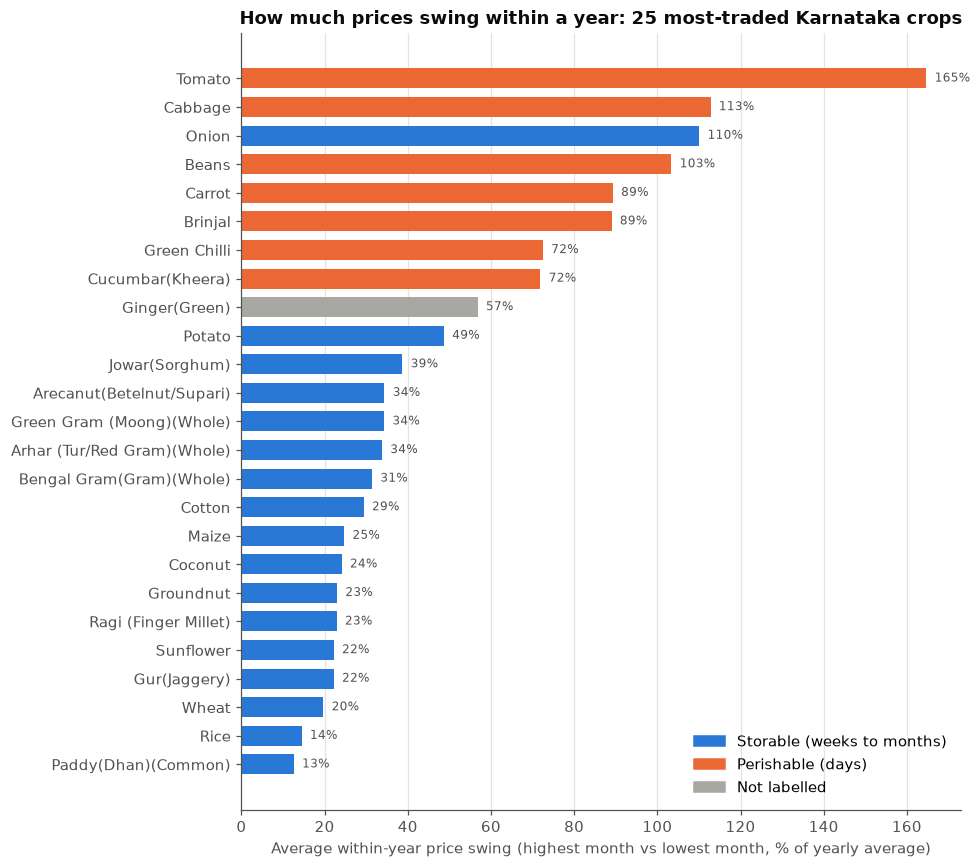

In [9]:
storability = {
    # perishable: days, sell almost immediately
    "Tomato": "Perishable", "Drumstick": "Perishable", "Beans": "Perishable", "Cabbage": "Perishable",
    "Brinjal": "Perishable", "Green Chilli": "Perishable", "Carrot": "Perishable", "Beetroot": "Perishable",
    "Capsicum": "Perishable", "Cauliflower": "Perishable", "Bhindi(Ladies Finger)": "Perishable",
    "Cucumbar(Kheera)": "Perishable", "Banana": "Perishable", "Banana - Green": "Perishable",
    # storable: weeks to months with suitable storage
    "Onion": "Storable", "Potato": "Storable", "Garlic": "Storable", "Dry Chillies": "Storable",
    "Ginger(Dry)": "Storable", "Turmeric": "Storable", "Maize": "Storable", "Jowar(Sorghum)": "Storable",
    "Ragi (Finger Millet)": "Storable", "Paddy(Dhan)(Common)": "Storable", "Rice": "Storable",
    "Wheat": "Storable", "Groundnut": "Storable", "Bengal Gram(Gram)(Whole)": "Storable",
    "Arhar (Tur/Red Gram)(Whole)": "Storable", "Green Gram (Moong)(Whole)": "Storable", "Cotton": "Storable",
    "Copra": "Storable", "Arecanut(Betelnut/Supari)": "Storable", "Sunflower": "Storable",
    "Gur(Jaggery)": "Storable", "Black pepper": "Storable", "Coconut": "Storable",
}
eligible["storage"] = eligible.index.map(storability).fillna("Not labelled")

# The 25 most-traded crops (by records), compared on within-year swing
top = eligible.sort_values("records", ascending=False).head(25).sort_values("within_year_swing_%")
colors = top["storage"].map({"Storable": BLUE, "Perishable": ORANGE}).fillna("#a8a7a1")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index.astype(str), top["within_year_swing_%"], color=colors, height=0.7)
for y, (v, n) in enumerate(zip(top["within_year_swing_%"], top.index)):
    ax.text(v + 2, y, f"{v:.0f}%", va="center", fontsize=8, color=MUTED)
ax.set_title("How much prices swing within a year: 25 most-traded Karnataka crops")
ax.set_xlabel("Average within-year price swing (highest month vs lowest month, % of yearly average)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Storable (weeks to months)"),
                   Patch(color=ORANGE, label="Perishable (days)"),
                   Patch(color="#a8a7a1", label="Not labelled")],
          loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Reading the chart.** Perishable vegetables (tomato, cabbage, beans) swing the most, but a farmer cannot hold
them, so the swing is a risk, not an opportunity. Among storable crops the swing differs a lot: onion's price
typically doubles within a year, while paddy and rice barely move (government procurement at support prices
is the likely reason, which is general knowledge, not tested here).

The best focus crops are **storable and volatile**, with **plenty of data**:

In [10]:
candidates = (eligible[eligible["storage"] == "Storable"]
              .sort_values("within_year_swing_%", ascending=False))
candidates[["records", "markets", "good_years", "within_year_swing_%", "month_to_month_vol_%"]].head(12)

,records,markets,good_years,within_year_swing_%,month_to_month_vol_%
Commodity,,,,,
Onion,93332,134,23,110.1,21.3
Ginger(Dry),6946,65,21,103.5,47.4
Garlic,16708,55,23,95.4,18.9
Potato,69012,110,23,48.7,12.3
Turmeric,7841,47,23,48.0,13.7
Jowar(Sorghum),90534,150,23,38.7,9.3
Copra,43071,76,23,38.5,10.4
Dry Chillies,40894,89,23,37.3,16.0
Arecanut(Betelnut/Supari),233687,121,23,34.4,27.1


## 5. Seasonal pattern of the candidate crops

A **seasonal index** shows each month's typical price relative to that year's average (100 = average).
If a crop is cheapest right after harvest and dearer some months later, storing can pay.

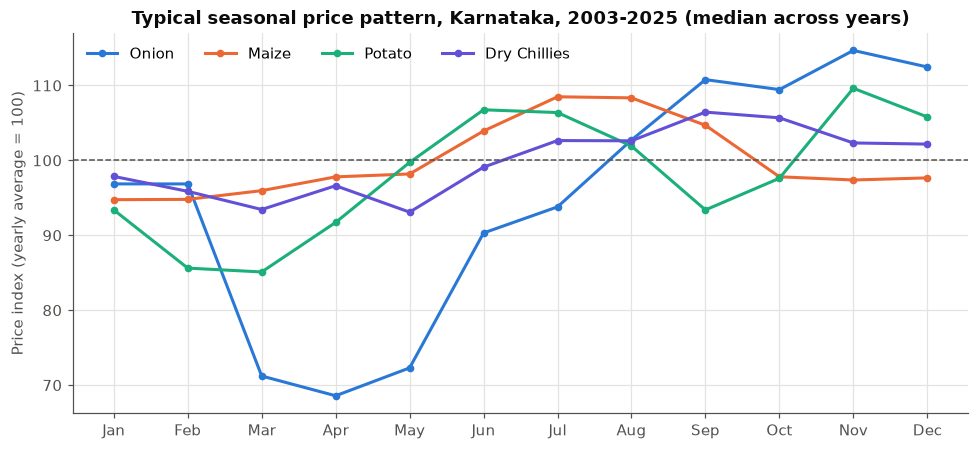

Cheapest and dearest month, and the gap between them:
              cheapest month  dearest month  gap (index points)
Commodity                                                      
Onion                      4             11                46.1
Maize                      1              7                13.7
Potato                     3             11                24.5
Dry Chillies               5              9                13.4


In [11]:
focus = ["Onion", "Maize", "Potato", "Dry Chillies"]
mp = monthly_price[monthly_price["Commodity"].isin(focus)].copy()
mp["Commodity"] = mp["Commodity"].astype(str)
mp["month"] = mp["ym"].dt.month
mp["index"] = mp["Modal_Price"] / mp.groupby(["Commodity", "year"])["Modal_Price"].transform("mean") * 100
seasonal = mp.groupby(["Commodity", "month"])["index"].median().unstack(0)[focus]

fig, ax = plt.subplots(figsize=(9, 4.2))
for name, color in zip(focus, [BLUE, ORANGE, AQUA, "#6250d6"]):
    ax.plot(seasonal.index, seasonal[name], color=color, linewidth=2, marker="o", markersize=4, label=name)
ax.axhline(100, color=MUTED, linewidth=1, linestyle="--")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Price index (yearly average = 100)")
ax.set_title("Typical seasonal price pattern, Karnataka, 2003-2025 (median across years)")
ax.legend(frameon=False, ncol=4, loc="upper left")
plt.tight_layout(); plt.show()

print("Cheapest and dearest month, and the gap between them:")
print(pd.DataFrame({"cheapest month": seasonal.idxmin(), "dearest month": seasonal.idxmax(),
                    "gap (index points)": (seasonal.max() - seasonal.min()).round(1)}))

## 6. Decision: focus crops

Fill this in from the outputs above (the numbers are produced by the cells, not typed by hand):

| Crop | Why it is in the project |
| --- | --- |
| **Onion** | Storable for weeks to months; the largest within-year swing of any well-covered storable crop (about 110%); cheapest around April and dearest around November; traded in 130+ mandis |
| **Maize** | Traded in more Karnataka mandis than any other crop, with a cheap season after harvest and a dearer one in mid-year, but a much smaller swing: the comparison case for whether storing still pays when prices move less |
| *(optional third)* | Potato or Dry Chillies, if time allows |

Everything from Notebook 2 onwards (cleaning detail, features, models, simulation, dashboard) uses only these crops.

In [12]:
# Save the focus-crop rows (all years, all checks still to be done in Notebook 2) for the next notebooks
FOCUS_CROPS = ["Onion", "Maize"]          # edit to add a third crop
subset = df[df["Commodity"].isin(FOCUS_CROPS)].copy()
subset.to_csv("../data/focus_crops_raw.csv", index=False)
print(f"Saved data/focus_crops_raw.csv: {len(subset):,} rows for {FOCUS_CROPS}")

Saved data/focus_crops_raw.csv: 267,369 rows for ['Onion', 'Maize']
